# Sorting algorithms

## bubble sort
Volgende prentje illustreert het basis idee van een bubble sort:

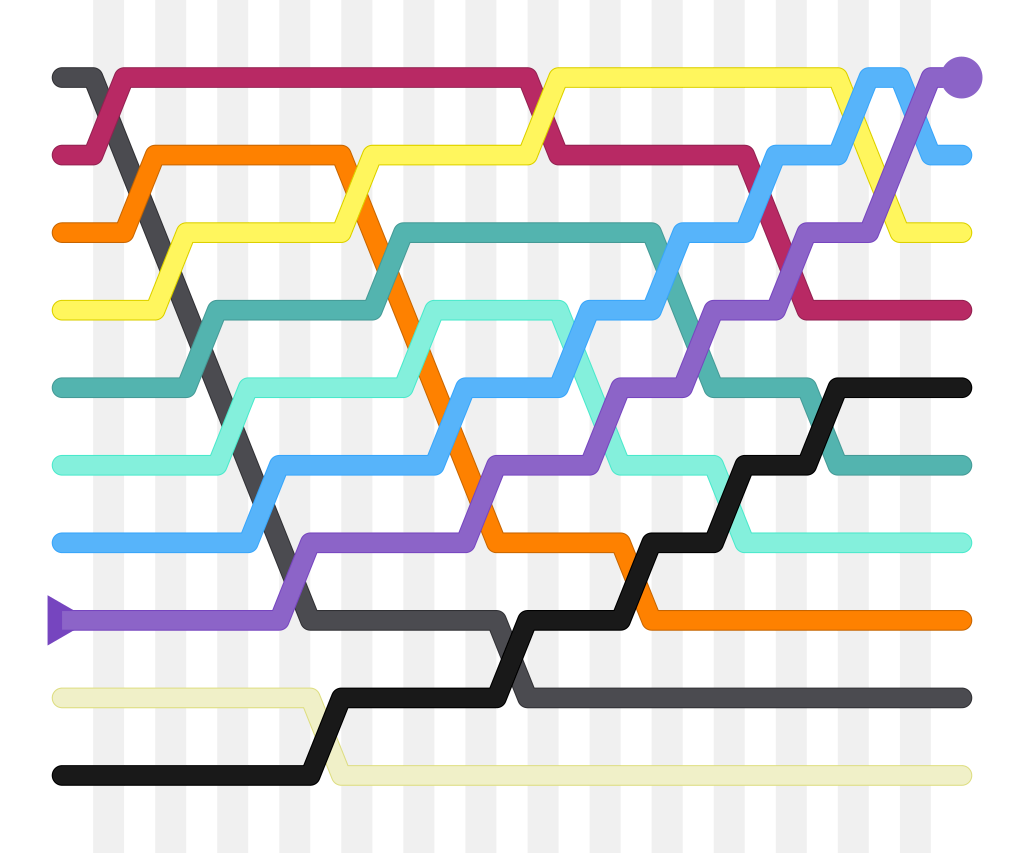

Items kunnen onderling worden vergeleken, en items kunnen ook enkel met hun buren van plaats wisselen. Het algroitme doorloopt de lijst en wisselt buren indien dit nodig is. Het algoritme blijft dit herhalen, tot het van kop tot teen door de lijst is gelopen zonder 1 wijziging te moeten uitvoeren, dan is het klaar.

In [2]:

def bubble_sort(sequence):
    n = len(sequence)
    for i in range(n-1):
        for j in range(n-i-1):
            if(sequence[j] > sequence[j+1]):
                sequence[j], sequence[j+1] = sequence[j+1], sequence[j] # wisselen van plaats

In [3]:
import random
sequence = random.sample(range(1000), 1000)
len(sequence)

1000

In [13]:
sequence

[988,
 722,
 814,
 802,
 23,
 67,
 984,
 836,
 3,
 592,
 562,
 314,
 698,
 962,
 517,
 297,
 104,
 532,
 253,
 189,
 411,
 220,
 42,
 538,
 292,
 500,
 283,
 563,
 29,
 593,
 653,
 691,
 902,
 662,
 675,
 652,
 229,
 31,
 949,
 62,
 26,
 706,
 793,
 294,
 234,
 207,
 178,
 325,
 778,
 436,
 907,
 337,
 194,
 105,
 998,
 732,
 775,
 567,
 409,
 959,
 668,
 6,
 789,
 815,
 893,
 785,
 378,
 51,
 296,
 896,
 808,
 728,
 438,
 224,
 313,
 935,
 106,
 488,
 930,
 600,
 272,
 480,
 307,
 171,
 739,
 710,
 353,
 93,
 213,
 596,
 355,
 44,
 372,
 88,
 399,
 978,
 587,
 822,
 467,
 702,
 882,
 583,
 485,
 552,
 382,
 798,
 646,
 456,
 279,
 573,
 599,
 277,
 616,
 515,
 373,
 365,
 38,
 48,
 338,
 540,
 57,
 170,
 929,
 548,
 487,
 999,
 403,
 492,
 906,
 595,
 534,
 835,
 918,
 182,
 578,
 176,
 383,
 142,
 727,
 126,
 9,
 129,
 604,
 354,
 797,
 621,
 414,
 933,
 177,
 543,
 242,
 779,
 883,
 858,
 464,
 708,
 533,
 72,
 47,
 964,
 976,
 941,
 268,
 384,
 54,
 556,
 499,
 672,
 60,
 832,
 291

### Dacorator om de lengte van een methode te meten
Meer info op https://realpython.com/python-timer/#a-python-timer-decorator

Bovendien willen we nog een argument aan de decorator meegevend, sud moeten we een extra level invoeren: https://stackoverflow.com/questions/10176226/how-do-i-pass-extra-arguments-to-a-python-decorator

In [14]:
from time import time

def timer_func(suppress_output=False):
    # dit geeft aan hoelang de functie die het meekrijgt heeft gerund
    def actual_decorator(func):
        def wrap_func(*args, **kwargs):
            t1 = time()
            result = func(*args, **kwargs)
            t2 = time()
            if not suppress_output:
                print(f'Function {func.__name__!r} executed in {(t2-t1):.4f}s')
            return result, t2-t1
        return wrap_func
    return actual_decorator

In [15]:
@timer_func(suppress_output=True) #using the decorator
def bubble_sort(sequence):
    n = len(sequence)
    for i in range(n-1):
        for j in range(n-i-1):
            if(sequence[j] > sequence[j+1]):
                sequence[j], sequence[j+1] = sequence[j+1], sequence[j] # switch places
    return sequence

In [16]:
tf = bubble_sort
result = tf(sequence)

Het resultaat is een tupple: op index 0 zit het resultaat van het sorteringsalgoritme, op index 1 de tijd die het nodig had en die gemeten is door de decorator.

In [19]:
result[1]

0.11466073989868164

In [29]:
r = 100
n = 4000 #max 5000

In [30]:
r = 100 #repitions
average_bubble = 0
for i in range(0,r):
    sequence = random.sample(range(n), n)
    result = bubble_sort(sequence)
    average_bubble += result[1] / r
print("Average time to complete: " + f'{(average_bubble):.4f}s')


Average time to complete: 1.8868s


## Merge sort
Een merge sort is geavanceerder en gebruikt een verdeel-en-heers strategie. Meer info op https://www.askpython.com/python/examples/merge-sort-in-python. Het gebruikt een recursieve strategie om het algoritme in stukjes op te delen.

In [26]:
@timer_func(suppress_output=True) #decorator gebruiken
def merge_sort(sequence):
    size = len(sequence)
    if size > 1:
        middle = size // 2
        left_arr = sequence[:middle]
        right_arr = sequence[middle:]
 
        merge_sort(left_arr)
        merge_sort(right_arr)
 
        p = 0
        q = 0
        r = 0
 
        left_size = len(left_arr)
        right_size = len(right_arr)
        while p < left_size and q < right_size:
            if left_arr[p] < right_arr[q]:
              sequence[r] = left_arr[p]
              p += 1
            else:
                sequence[r] = right_arr[q]
                q += 1
             
            r += 1
 
        
        while p < left_size:
            sequence[r] = left_arr[p]
            p += 1
            r += 1
 
        while q < right_size:
            sequence[r]=right_arr[q]
            q += 1
            r += 1

In [27]:
average_merge = 0
for i in range(0,r):
    sequence = random.sample(range(n), n)
    result = merge_sort(sequence)
    average_merge += result[1] / r
print("Gemiddelde tijd om sortering te voltooien: " + f'{(average_merge):.4f}s')

Average time to complete: 0.0113s


## Verschil vergelijken

In [28]:
average_bubble/average_merge

37.95214060471117